# Member 1 - Housing dataset and EDA
**Original contributor:** Mostafa. **Dataset H5:** [DOB NOW Build Job Application Filings](https://data.cityofnewyork.us/Housing-Development/DOB-NOW-Build-Job-Application-Filings/w9ak-ipjd).

We study application activity, not completed homes. The full 2022-2025 filing window is used, not a row-limited sample. This revised notebook fixes the earlier unit double-counting and uses the building `postcode` field now verified in the live API. `zip` remains the owner's mailing ZIP and is never a building-location key.

Run Member 2's cleaning section first (its row-level CSV is also committed). Member 3 alone writes the final integrated CSV. Helpers contain the tested cleaning logic; all decisions and results are visible here.

This enhancement keeps the existing cleaning and export policy. Richer EDA and reporting-coverage plots are supplemented by explicitly hypothetical plausibility checks: their flags never remove values from the exported dataset.

**Integrated RQ1 execution order:** housing/transportation preparation must finish before Member 3 exports the integrated CSV. Member 1's research then reads that fresh integrated table. The final consolidated notebook places this research after the integration export; `run_notebooks.py` splits Member 1 preparation and research to enforce the same dependency.

## 1. Environment and reproducible paths
Resolve files from the repository, without creating duplicate data folders inside notebooks.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "data").is_dir():
    ROOT = ROOT.parent
assert (ROOT / "members").is_dir(), "Run from the repository root or notebooks directory."
CLEAN_DIR = ROOT / "data" / "clean"
RAW_DIR = ROOT / "data" / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)
CLEAN_DIR.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
sys.path.insert(0, str(ROOT / "members" / "member3_integration"))
sns.set_theme(style="whitegrid")
plt.rcParams["figure.dpi"] = 80
pd.set_option("display.max_columns", 50)
BOROUGH_ORDER = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
BOROUGH_COLORS = dict(zip(BOROUGH_ORDER, sns.color_palette("colorblind", 5)))

## 2. Source, columns and complete-window download
The API has geography (`borough`, `postcode`, latitude/longitude), time (`filing_date`), identity (`job_filing_number`), building measures, cost and `job_type`. It also contains many personal/administrative fields that are not needed.

The downloader explicitly selects analysis columns, filters 2022-2025, pages in stable ID order, and checks its row count against the server count. A cached raw CSV is used explicitly, never as a hidden fallback after a failed download. Delete it to request a refresh; a companion JSON records provenance. Missing required fields fail with a clear error.

In [2]:
from fetch_h5_data import main as download_housing
housing_raw_path = RAW_DIR / "w9ak-ipjd.csv"
if not housing_raw_path.exists():
    download_housing()
print(f"Reading explicit raw cache: {housing_raw_path}")
df_raw = pd.read_csv(housing_raw_path, low_memory=False)
print(f"Raw shape: {df_raw.shape[0]:,} rows x {df_raw.shape[1]} columns")
display(df_raw.head())
display(df_raw.dtypes.to_frame("dtype"))

Reading explicit raw cache: C:\Users\t-pnassef\OneDrive - Microsoft\Desktop\nyc-housing-transport\data\raw\w9ak-ipjd.csv


Raw shape: 598,706 rows x 38 columns


,job_filing_number,filing_date,filing_status,borough,block,lot,bin,commmunity_board,house_no,street_name,zip,building_type,initial_cost,total_construction_floor_area,existing_stories,existing_height,existing_dwelling_units,proposed_no_of_stories,proposed_height,proposed_dwelling_units,latitude,longitude,council_district,census_tract,nta,first_permit_date,approved_date,current_status_date,work_on_floor,apt_condo_no_s,special_inspection_agency_number,signoff_date,built_1_information_value,built_2_information_value,built_2_a_information_value,built_2_b_information_value,postcode,job_type
0,B00244768-P3,2022-05-18T00:00:00.000,Approved,Brooklyn,1987,21,3057064,303.0,22,MONROE STREET,11101,2 Family,12500.0,1734.0,NaN,NaN,2.0,NaN,NaN,2.0,40.684585,-73.958175,36.0,229.0,Bedford-Stuyvesant (West),NaN,2022-06-02T13:28:51.000,2022-06-02T17:28:54.000,"Cellar, Floor Number(s) 2 through 3, Floor Num...","Apr A, Apt B",001310,NaN,NaN,NaN,NaN,NaN,11238.0,Alteration
1,B00464221-S2,2023-11-11T00:00:00.000,Permit Entire,Brooklyn,1566,4,3042533,316.0,29,MARCONI PLACE,11435,2 Family,0.0,1456.0,2.0,24.0,2.0,2.0,24.0,2.0,40.676822,-73.912718,41.0,301.0,Ocean Hill,2025-09-12T00:00:00.000,2023-11-13T15:26:00.000,2025-09-12T19:20:57.000,"Cellar, Floor Number(s) 2 through 2",NaN,004288,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
2,B00451661-P2,2023-12-26T00:00:00.000,Approved,Brooklyn,1904,36,3054870,302.0,164,HALL STREET,18064,3 Family,77500.0,400.0,NaN,NaN,3.0,NaN,NaN,3.0,40.692927,-73.965814,35.0,195.0,Clinton Hill,NaN,2024-01-02T23:15:25.000,2024-01-03T04:15:25.000,"Basement/Sub-basement, Floor Number(s) 1 throu...",NaN,000930,NaN,NaN,NaN,NaN,NaN,11205.0,Alteration
3,B00461532-P2,2023-11-21T00:00:00.000,Approved,Brooklyn,1452,66,3413799,316.0,1481,ST MARKS AVENUE,11040,Other,5500.0,1.0,NaN,NaN,77.0,NaN,NaN,77.0,40.673494,-73.918516,41.0,303.0,Ocean Hill,NaN,2023-11-22T11:28:12.000,2023-11-22T16:28:13.000,Open Space,NaN,NaN,NaN,NaN,NaN,NaN,NaN,11233.0,Alteration
4,B00360987-P2,2023-01-03T00:00:00.000,Approved,Brooklyn,2989,32,3070595,301.0,53,SCOTT AVENUE,76262,Other,100000.0,23825.0,NaN,NaN,0.0,NaN,NaN,0.0,40.709520,-73.922576,34.0,44902.0,East Williamsburg,NaN,2023-01-17T15:17:56.000,2023-01-18T16:16:44.000,"Floor Number(s) 001 through 005, Roof",NaN,1688,NaN,NaN,NaN,NaN,NaN,11237.0,Alteration


,dtype
job_filing_number,str
filing_date,str
filing_status,str
borough,str
block,int64
lot,int64
bin,int64
commmunity_board,float64
house_no,str
street_name,str


## 3. EDA: missing values, duplicates and distributions
Inspect the observed data rather than copying percentages from an older sample. Count duplicate filing IDs separately from exact duplicate rows and distinguish filings from jobs. The 60% missingness threshold applies only to optional columns; analysis measures remain available without imputation.

Raw memory footprint: 726.2 MB


,missing_count,missing_share
apt_condo_no_s,594039,0.992205
built_2_information_value,537403,0.897608
built_1_information_value,537403,0.897608
built_2_b_information_value,537403,0.897608
built_2_a_information_value,537403,0.897608
signoff_date,360722,0.602503
existing_height,351145,0.586507
existing_stories,335471,0.560327
proposed_height,316179,0.528104
proposed_no_of_stories,300349,0.501664


Exact duplicate rows: 0
Duplicate filing IDs: 55


Unique filing IDs: 598,651; unique job prefixes: 346,714


,count,mean,std,min,25%,50%,75%,max
filings per job,346714.0,1.726801,1.684103,1.0,1.0,1.0,2.0,40.0


,count,mean,std,min,1%,50%,95%,99%,max
initial_cost,598706.0,273867.99,3665479.97,0.00,0.00,25000.00,750126.14,3813351.20,8.000100e+08
total_construction_floor_area,556180.0,22849.88,1306096.55,0.00,1.00,1940.00,71138.00,328590.00,7.700100e+08
existing_stories,263235.0,12.60,415.44,0.00,1.00,4.00,38.00,60.00,9.250100e+04
existing_height,247561.0,117.03,3266.08,0.00,8.00,44.00,404.00,755.00,7.962650e+05
existing_dwelling_units,512658.0,259.98,155187.28,0.00,0.00,2.00,210.00,495.00,1.111111e+08
proposed_no_of_stories,298357.0,12.21,396.18,0.00,1.00,4.00,36.00,59.00,9.250100e+04
proposed_height,282527.0,115.78,3078.33,0.00,10.00,49.00,386.00,750.00,7.962650e+05
proposed_dwelling_units,550003.0,45.73,1144.69,0.00,0.00,2.00,222.00,515.00,3.254370e+05
latitude,596323.0,40.73,0.07,40.50,40.54,40.73,40.85,40.88,4.091000e+01
longitude,596323.0,-73.94,0.08,-74.25,-74.18,-73.96,-73.79,-73.74,-7.370000e+01


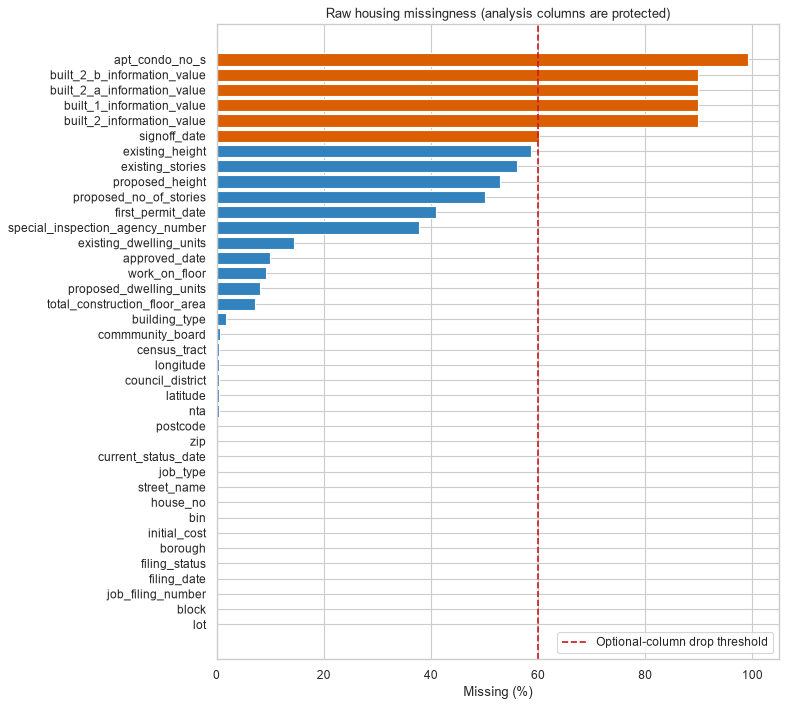

In [3]:
print(f"Raw memory footprint: {df_raw.memory_usage(deep=True).sum() / 1024 ** 2:,.1f} MB")
missing = df_raw.isna().mean().sort_values(ascending=False)
display(pd.DataFrame({"missing_count": df_raw.isna().sum(), "missing_share": df_raw.isna().mean()})
        .sort_values("missing_share", ascending=False))
print("Exact duplicate rows:", df_raw.duplicated().sum())
print("Duplicate filing IDs:", df_raw.duplicated("job_filing_number").sum())
raw_jobs = df_raw["job_filing_number"].astype("string").str.split("-").str[0]
print(f"Unique filing IDs: {df_raw['job_filing_number'].nunique():,}; unique job prefixes: {raw_jobs.nunique():,}")
display(raw_jobs.value_counts().describe().to_frame("filings per job").T)
from housing_pipeline import NUMERIC
raw_num = df_raw[NUMERIC].apply(pd.to_numeric, errors="coerce")
display(raw_num.describe(percentiles=[0.01, 0.5, 0.95, 0.99]).T.round(2))
plot_missing = missing.sort_values()
fig, ax = plt.subplots(figsize=(10, 9))
ax.barh(plot_missing.index, plot_missing * 100,
        color=["#d95f02" if value > 0.6 else "#3182bd" for value in plot_missing])
ax.axvline(60, color="#cb181d", linestyle="--", label="Optional-column drop threshold")
ax.set(title="Raw housing missingness (analysis columns are protected)", xlabel="Missing (%)", xlim=(0, 105))
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

### Owner ZIP versus building postcode
The owner mailing ZIP is not the construction-site ZIP. Compare reported values to demonstrate the distinction; numeric presence alone does not establish a valid NYC ZIP. The cleaner applies its documented screening and never uses owner ZIP as a building key.

In [4]:
building_zip = pd.to_numeric(df_raw["postcode"], errors="coerce")
owner_zip = pd.to_numeric(df_raw["zip"].astype("string").str.strip().str[:5], errors="coerce")
both_zips = building_zip.notna() & owner_zip.notna()
owner_in_range = owner_zip.between(10001, 10499) | owner_zip.between(11001, 11699)
zip_audit = pd.DataFrame([
    ("Both ZIPs reported numerically", int(both_zips.sum()), len(df_raw)),
    ("Owner ZIP differs from building postcode", int((both_zips & building_zip.ne(owner_zip)).sum()), int(both_zips.sum())),
    ("Owner ZIP outside broad NYC numeric ranges", int((owner_zip.notna() & ~owner_in_range).sum()), int(owner_zip.notna().sum())),
    ("Building postcode missing/non-numeric", int(building_zip.isna().sum()), len(df_raw)),
], columns=["check", "filings", "denominator"])
zip_audit["share"] = zip_audit["filings"] / zip_audit["denominator"].replace(0, np.nan)
display(zip_audit)

,check,filings,denominator,share
0,Both ZIPs reported numerically,597547,598706,0.998064
1,Owner ZIP differs from building postcode,581195,597547,0.972635
2,Owner ZIP outside broad NYC numeric ranges,153543,598195,0.256677
3,Building postcode missing/non-numeric,648,598706,0.001082


### Domain checks and review candidates
Unknown values are excluded from violation counts. Hard validity checks follow the existing cleaner. The three checks marked **review only** are judgment-based screening ideas, not proof of errors: construction floor area need not represent all finished residential space, low-rise developments can be large, and unusually expensive small-house work requires review. Section 6 compares their hypothetical effects without changing exports.

In [5]:
from housing_diagnostics import housing_domain_flags, housing_sensitivity
raw_domain_flags = housing_domain_flags(df_raw)
display(raw_domain_flags.sum().rename("flagged_filings").to_frame())
print("Checks can overlap; review candidates are not automatically quarantined.")

,flagged_filings
"Negative units, cost or floor area",0
Non-integer reported dwelling units,0
"Dwelling units above 10,000",22
"Height above 2,000 ft",134
Stories above 150,515
Small-house high cost (review only),10
Low-rise high units (review only),20
Unit gain with low construction area (review only),8829
Observed coordinates outside NYC bounds,0
Known borough differs from known job prefix,24


Checks can overlap; review candidates are not automatically quarantined.


### Initial geography, time and outliers
Inspect geography and time together, filing statuses, and the long tails in costs and units. A log-scaled distribution makes large values readable; neither a long tail nor a zero report establishes an error.

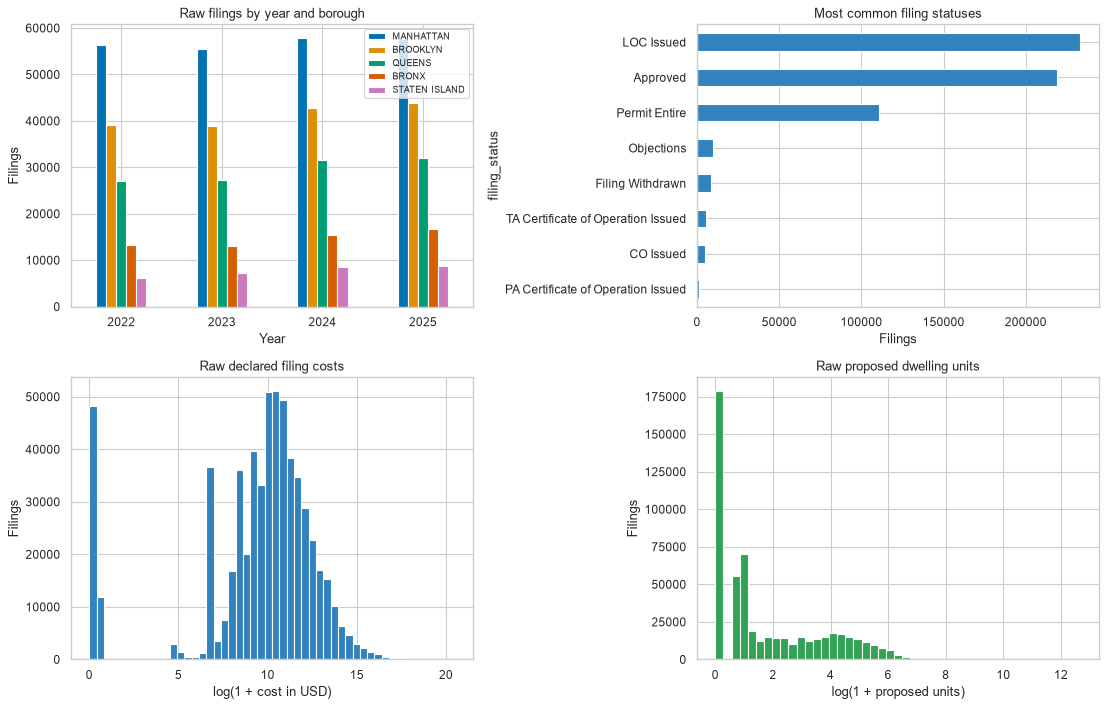

**Observed:** 8.0% of all raw filings report zero initial cost. Unit and cost reports have long tails; the distributions alone do not validate or invalidate a report.

In [6]:
dates = pd.to_datetime(df_raw["filing_date"], format="mixed", errors="coerce")
raw_cost = raw_num["initial_cost"]
raw_units = raw_num["proposed_dwelling_units"]
raw_stories = raw_num["proposed_no_of_stories"]
raw_borough = df_raw["borough"].astype("string").str.strip().str.upper()
fig, axes = plt.subplots(2, 2, figsize=(14, 9))
pd.crosstab(dates.dt.year, raw_borough).reindex(columns=BOROUGH_ORDER).plot.bar(
    ax=axes[0, 0], color=[BOROUGH_COLORS[b] for b in BOROUGH_ORDER])
axes[0, 0].set(title="Raw filings by year and borough", xlabel="Year", ylabel="Filings")
axes[0, 0].tick_params(axis="x", rotation=0)
axes[0, 0].legend(fontsize=8)
df_raw["filing_status"].value_counts().head(8).sort_values().plot.barh(ax=axes[0, 1], color="#3182bd")
axes[0, 1].set(title="Most common filing statuses", xlabel="Filings")
axes[1, 0].hist(np.log1p(raw_cost[raw_cost >= 0]), bins=50, color="#3182bd")
axes[1, 0].set(title="Raw declared filing costs", xlabel="log(1 + cost in USD)", ylabel="Filings")
axes[1, 1].hist(np.log1p(raw_units[raw_units >= 0]), bins=45, color="#31a354")
axes[1, 1].set(title="Raw proposed dwelling units", xlabel="log(1 + proposed units)", ylabel="Filings")
plt.tight_layout()
plt.show()
display(Markdown(f"**Observed:** {raw_cost.eq(0).mean():.1%} of all raw filings report zero initial cost. "
                 "Unit and cost reports have long tails; the distributions alone do not validate or invalidate a report."))

## 4. Pre-integration cleaning: drop versus impute
1. **Drop** completely empty rows, unusable filing IDs, invalid dates/out-of-window years and invalid boroughs: these cannot be assigned reliable integration keys. Keep the latest status snapshot per filing ID. Drop borough/job-prefix conflicts because their location is ambiguous.
2. **Drop optional columns above 60% missing**, while protecting analysis fields even if sparse. No invented heights, units or costs.
3. **Keep the filing, quarantine the measure:** negative costs/areas, heights outside 0-2,000 feet, stories outside 0-150, and non-integer/negative dwelling units become missing. Unit values over **10,000 per job** are a conservative screening rule, not a verified correction; they become missing for review. In particular, a repeated-digit value such as 111,111,111 cannot dominate housing totals. Large plausible costs/areas/units remain and receive log-scale IQR flags.
4. **Missing existing units are not zero.** A blank does not prove a new building. Use the actual `job_type == "New Building"` label for new-building filing counts.
5. **Official building `postcode` first.** For missing/invalid postcode only, use the existing nearest-SIRTA-crash ZIP method within 0.01 degrees and flag it `nearest_crash`. This distance is approximate and is not an official boundary lookup. Invalid coordinates become missing. Drop rows only if neither method supplies a ZIP. The owner `zip` is never used.

The table below reports the actual rows and decisions. Geographic ZIP validity uses a broad NYC numeric screening range, not a USPS directory. Nearest-crash assignments may create coverage bias and boundary error; no unverified percentage is treated as measured accuracy.

In [7]:
from housing_pipeline import clean_housing, aggregate_housing
df_housing, cleaning_log = clean_housing(df_raw, CLEAN_DIR / "transport_clean_row_level.csv")
display(cleaning_log)
display(df_housing["zip_assignment_method"].value_counts().to_frame("filings"))
display(df_housing[["unit_value_quarantined", "outlier_flag"]].sum().to_frame("filings"))

ZIP assigned to 20.4% of filings (673 left missing).


,step,rows,note
0,Raw,598706,"Complete 2022-2025 download, not a row-limited..."
1,Keys and duplicates,598631,Drop invalid IDs/dates/boroughs; keep latest s...
2,Sparse optional columns,598631,Drop >60% missing optional columns: ['apt_cond...
3,Invalid measures,598631,Keep filings; set impossible measures to NaN. ...
4,Location consistency,598607,Drop borough/job-prefix conflicts; invalid coo...
5,Building ZIP,597934,Official postcode first; 173 flagged approxima...
6,Outliers,597934,Keep high but plausible values and flag using ...


,filings
zip_assignment_method,
official_postcode,597761
nearest_crash,173


,filings
unit_value_quarantined,22
outlier_flag,12162


## 5. Cleaning validation
Compare before/after counts, missingness and unit distributions. Known-invalid measures are quarantined under the existing policy; plausible extremes remain flagged, not removed. The scatter plots use reproducible samples of up to 40,000 filings each; the audits and exports always use all retained records.

,metric,before,after
0,Rows,598706.0,597934.0
1,Duplicate filing IDs,55.0,0.0
2,Missing proposed units,48703.0,48662.0
3,Max proposed units,325437.0,9950.0
4,Max initial cost (USD),800010000.0,800010000.0


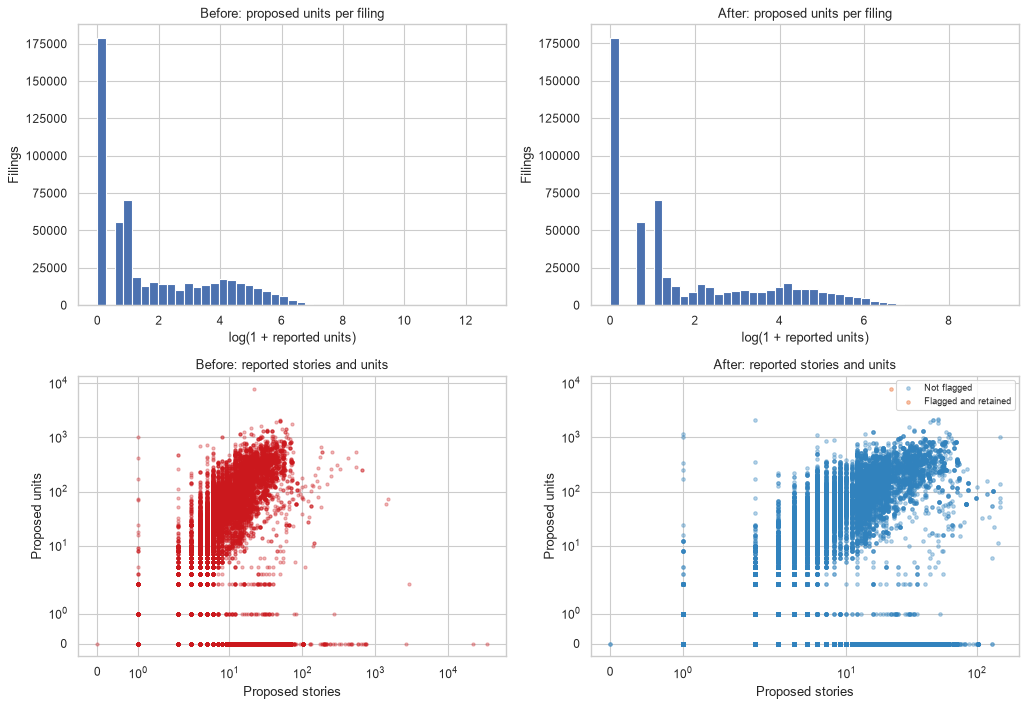

In [8]:
display(pd.DataFrame({
    "metric": ["Rows", "Duplicate filing IDs", "Missing proposed units", "Max proposed units", "Max initial cost (USD)"],
    "before": [len(df_raw), df_raw.duplicated("job_filing_number").sum(), raw_units.isna().sum(), raw_units.max(), raw_cost.max()],
    "after": [len(df_housing), df_housing.duplicated("job_filing_number").sum(), df_housing["proposed_dwelling_units"].isna().sum(),
              df_housing["proposed_dwelling_units"].max(), df_housing["initial_cost"].max()],
}))
assert not df_housing["job_filing_number"].duplicated().any()
assert df_housing["zip_code"].str.fullmatch(r"\d{5}").all()
assert df_housing["year"].isin([2022, 2023, 2024, 2025]).all()
assert set(df_housing["borough"]) <= set(BOROUGH_ORDER)
assert all(column == column.lower() and " " not in column for column in df_housing)
clean_domain_flags = housing_domain_flags(df_housing)
hard_checks = [column for column in clean_domain_flags if "review only" not in column]
assert not clean_domain_flags[hard_checks].any().any()
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, values, label in [(axes[0, 0], raw_units, "Before"),
                          (axes[0, 1], df_housing["proposed_dwelling_units"], "After")]:
    ax.hist(np.log1p(values[values >= 0]), bins=45)
    ax.set(title=f"{label}: proposed units per filing", xlabel="log(1 + reported units)", ylabel="Filings")
before_scatter = pd.DataFrame({"stories": raw_stories, "units": raw_units}).dropna()
before_scatter = before_scatter.sample(n=min(40_000, len(before_scatter)), random_state=29735)
axes[1, 0].scatter(before_scatter["stories"], before_scatter["units"], s=8, alpha=0.3, color="#cb181d")
axes[1, 0].set(title="Before: reported stories and units", xlabel="Proposed stories", ylabel="Proposed units",
               xscale="symlog", yscale="symlog")
after_scatter = df_housing[["proposed_no_of_stories", "proposed_dwelling_units", "outlier_proposed_units"]].dropna()
after_scatter = after_scatter.sample(n=min(40_000, len(after_scatter)), random_state=29735)
for flagged, label, color in [(False, "Not flagged", "#3182bd"), (True, "Flagged and retained", "#e6550d")]:
    subset = after_scatter[after_scatter["outlier_proposed_units"].eq(flagged)]
    axes[1, 1].scatter(subset["proposed_no_of_stories"], subset["proposed_dwelling_units"],
                       s=10, alpha=0.35, label=label, color=color)
axes[1, 1].set(title="After: reported stories and units", xlabel="Proposed stories", ylabel="Proposed units",
               xscale="symlog", yscale="symlog")
axes[1, 1].legend(fontsize=8)
plt.tight_layout()
plt.show()

## 6. Aggregate to ZIP code x year without double-counting jobs
`filing_count` counts distinct filing IDs, including amendments. Unit totals must not count the same building-unit report once for every amendment.

Extract the base `job_id` before the filing suffix. Each job contributes **one complete existing/proposed unit pair**, taken from its latest valid filing in this window. Attribute that pair to the ZIP and year of its **first observed filing in 2022-2025**. This is a window-defined job cohort, not necessarily its original lifetime filing year. A job with no complete pair remains unknown; we do not borrow one side from another filing or invent zero units. Negative net changes are allowed.

`unique_job_count` and `jobs_with_known_units` reveal coverage. ZIP-years with no first-observed jobs have zero cohort units; if jobs exist but none report a complete pair, totals stay missing. Partial sums cover reporting jobs only. These are reported job/building-unit quantities, **not completed housing supply**. The four-year job totals can be summed without counting a job twice.

Declared cost and floor-area totals remain **filing-level reported amounts**, which may overlap across related filings; they are not a unique investment total. Official/approximate ZIP counts remain available for sensitivity checks.

In [9]:
df_housing_agg, housing_jobs = aggregate_housing(df_housing)
assert df_housing_agg["filing_count"].sum() == len(df_housing)
assert df_housing_agg["unique_job_count"].sum() == df_housing["job_id"].nunique()
assert df_housing_agg["official_zip_filings"].add(df_housing_agg["approximate_zip_filings"]).equals(df_housing_agg["filing_count"])
np.testing.assert_allclose(df_housing_agg["proposed_units_total"] - df_housing_agg["existing_units_total"],
                           df_housing_agg["net_new_units"], equal_nan=True)
df_housing.to_csv(CLEAN_DIR / "housing_clean_row_level.csv", index=False)
df_housing_agg.to_csv(CLEAN_DIR / "housing_clean.csv", index=False)
print(f"Saved housing_clean.csv: {len(df_housing_agg):,} ZIP-years, {df_housing_agg.shape[1]} columns")
known = int(housing_jobs["proposed_dwelling_units"].notna().sum())
print(f"Unique jobs: {len(housing_jobs):,}; complete reported unit pairs: {known:,} ({known / len(housing_jobs):.1%})")
display(df_housing_agg.head())
display(df_housing_agg.dtypes.to_frame("dtype"))

Saved housing_clean.csv: 877 ZIP-years, 23 columns
Unique jobs: 346,294; complete reported unit pairs: 298,176 (86.1%)


,zip_code,year,borough,filing_count,new_construction_filings,permit_issued_count,initial_cost_total,initial_cost_median,total_floor_area,avg_proposed_stories,avg_proposed_height,avg_latitude,avg_longitude,outlier_filing_count,outlier_filing_share,official_zip_filings,approximate_zip_filings,unique_job_count,jobs_with_known_units,proposed_units_total,existing_units_total,net_new_units,is_outlier_zip_year
0,10001,2022,MANHATTAN,2659,9,1260,1.118761e+09,25000.00,9.350611e+07,22.886898,288.375479,40.749995,-73.995301,93,0.034976,2659,0,2182,1939,103971.0,96716.0,7255.0,True
1,10001,2023,MANHATTAN,2567,18,1124,1.762834e+09,34999.44,6.568540e+07,25.262959,353.155556,40.750120,-73.995315,93,0.036229,2567,0,1641,1392,71383.0,70768.0,615.0,True
2,10001,2024,MANHATTAN,2650,8,1201,1.146879e+09,38748.50,5.963017e+07,31.220197,461.863192,40.750026,-73.995652,64,0.024151,2650,0,1469,1188,42551.0,41235.0,1316.0,True
3,10001,2025,MANHATTAN,2532,33,833,1.210055e+09,36750.00,4.061151e+07,25.937788,369.956911,40.749856,-73.995030,45,0.017773,2532,0,1372,1107,42749.0,41515.0,1234.0,True
4,10002,2022,MANHATTAN,1334,35,598,3.446611e+08,17500.00,1.192265e+08,10.789077,105.637450,40.717120,-73.988388,66,0.049475,1334,0,1050,996,96736.0,93937.0,2799.0,False


,dtype
zip_code,str
year,int64
borough,string
filing_count,int64
new_construction_filings,Int64
permit_issued_count,int64
initial_cost_total,float64
initial_cost_median,float64
total_floor_area,float64
avg_proposed_stories,float64


### Sensitivity analysis: hypothetical exclusions, not cleaning rules
Compare the exported baseline with three proposed review rules: fewer than **300 sq ft of construction area per net added unit** (known area only), **at most 4 stories and more than 500 proposed units**, and **1/2/3-family costs above $25M**. Each scenario operates on a copy, keeps every filing, and applies the same one-pair-per-job accounting. An earlier valid pair may become the latest usable pair after a hypothetical quarantine.

These thresholds are not independently validated. Large changes reveal methodological sensitivity, not which total is correct. Neither the baseline nor a scenario is a count of completed homes. Scenario values are never exported, and baseline unit/cost values and log-IQR flags remain unchanged.

In [10]:
sensitivity = housing_sensitivity(df_housing)
assert sensitivity["filing_count"].eq(len(df_housing)).all()
np.testing.assert_allclose(sensitivity.iloc[0]["reported_net_units"],
                           housing_jobs["net_new_units"].sum(min_count=1), equal_nan=True)
display(sensitivity.round(2))
combined_change = sensitivity.loc["All three review rules", "net_units_vs_baseline"]
display(Markdown(f"**Sensitivity:** all three hypothetical rules change the reported net total by {combined_change:+,.0f} units "
                 "relative to the exported baseline. This is a reason to investigate flagged reports, not to assume the alternative is correct. "
                 "All subsequent research charts use the unchanged baseline."))

,flagged_filings,filing_count,jobs_with_known_units,reported_net_units,reported_cost_usd,net_units_vs_baseline
scenario,,,,,,
Baseline: exported policy,0,597934,298176,663682.0,1.638509e+11,0.0
Construction area rule only,8797,597934,293418,235879.0,1.638509e+11,-427803.0
Low-rise unit rule only,20,597934,298159,663452.0,1.638509e+11,-230.0
Small-house cost rule only,10,597934,298176,663682.0,1.632226e+11,0.0
All three review rules,8826,597934,293402,235879.0,1.632226e+11,-427803.0


**Sensitivity:** all three hypothetical rules change the reported net total by -427,803 units relative to the exported baseline. This is a reason to investigate flagged reports, not to assume the alternative is correct. All subsequent research charts use the unchanged baseline.

## 7. Member 1 research using the integrated dataset
Run the housing preparation/export first, then Member 3's integration, and only then this research section. The shared reproduction runner follows that order. These questions read the authoritative integrated CSV without overwriting it.

### RQ1. Do ZIP-years with taller proposed building profiles have a different serious-injury burden per recorded crash?
**Why it matters:** New Yorkers need housing and safe streets. Development-profile and safety reviews should be coordinated, without treating taller proposed profiles as proof of danger or safety.

**What changed:** the previous borough/year heatmap used only housing-unit totals. This original integrated-data visualization connects DOB's reported mean proposed stories with SIRTA's seriously injured people and serious-crash counts. It is not another filing/crash count correlation or unit-change comparison.

**Method:** assign annual NYC-wide quartile groups of positive `avg_proposed_stories` among housing-covered ZIPs, before scope filters or zero-crash exclusions. Ties stay together. For ZIP-years with a usable profile and `crash_count > 0`, calculate `severe_injuries_total / crash_count`. Boxes and points show the ZIP-year distributions; orange diamonds show summed injuries divided by summed crashes, not averages of ZIP ratios. Missing profiles and zero-crash denominators are excluded from this question, not turned into zeros.

**Limits and impact:** a filing-derived story average is not the height of every building or evidence of completed construction. This ratio describes recorded-event injury burden, not personal risk. Reporting, density, exposure and actual construction timing can confound the pattern; correlation is not causation. DOT, housing planners and community boards can use the findings to frame street-level investigation, then obtain traffic/pedestrian counts and actual work-zone dates before decisions.

In [1]:
import sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "app" / "data.py").is_file():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT))
sys.path.insert(0, str(ROOT / "members" / "member1_housing"))
from app.data import Selection, build_report, load_dataset, building_profile_findings, PROFILE_BENCHMARK_NOTE
from app.charts import building_profile_figure

BOROUGH_ORDER = ["MANHATTAN", "BROOKLYN", "QUEENS", "BRONX", "STATEN ISLAND"]
BOROUGH_COLORS = dict(zip(BOROUGH_ORDER, sns.color_palette("colorblind", 5)))
housing_integrated = load_dataset()
profile_report = build_report(housing_integrated, Selection())
building_profile_figure(profile_report).show(renderer="plotly_mimetype")
profile_finding, profile_surprise = building_profile_findings(profile_report)
display(Markdown("**Calculated RQ1 finding:** " + profile_finding))
display(Markdown("**What challenges the simple story:** " + profile_surprise))
display(Markdown(PROFILE_BENCHMARK_NOTE))
display(profile_report.profile_summary.round(4))
display({
    "eligible_zip_years": profile_report.coverage["building_profile_rows"],
    "unknown_housing_rows": profile_report.coverage["unknown_housing_rows"],
    "missing_or_nonpositive_profile_rows": profile_report.coverage["unknown_building_profile_rows"],
    "profile_rows_with_zero_recorded_crashes": profile_report.coverage["zero_crash_profile_rows"],
})
display(Markdown(
    "**Interpretation and action:** group medians and pooled ratios answer different descriptive questions. "
    "The outcome is injured people per recorded serious crash, not a population-adjusted risk estimate. "
    "DOT and housing planners should verify local traffic/pedestrian exposure and actual construction dates "
    "before acting on the pattern; it cannot establish a building-height effect."
))

# RQ2 retains the housing-covered population, including documented structural crash zeros.
housing_analysis = housing_integrated.loc[housing_integrated["has_housing_data"]].copy()


**Calculated RQ1 finding:** Across 697 eligible ZIP-years in 183 ZIPs, group medians range from 1.00 to 1.00 people seriously injured per recorded serious crash. Ratios of pooled injury/crash counts range from 1.00 to 1.05.

**What challenges the simple story:** All 4 observed building-profile groups share a median of 1.00, despite different proposed-story profiles. Equal medians do not establish equal distributions or equal risk.

Building-profile groups use each year's NYC-wide housing-covered ZIPs with a positive reported mean of proposed stories, before scope filters or zero-crash exclusions. Ties stay together. These are filing-derived profiles, not the height of every building or evidence that construction took place.

,zip_years,severe_injuries,recorded_crashes,median_injuries_per_crash,min_reported_stories,max_reported_stories,pooled_injuries_per_crash
building_profile_group,,,,,,,
Q1 / lowest,197,2073,1979,1.0,1.7042,2.9441,1.0475
Q2,214,4134,4080,1.0,2.8259,5.2299,1.0132
Q3,213,3749,3660,1.0,4.8040,15.4147,1.0243
Q4 / highest,73,809,807,1.0,14.3255,52.0000,1.0025


{'eligible_zip_years': 697,
 'unknown_housing_rows': 4,
 'missing_or_nonpositive_profile_rows': 8,
 'profile_rows_with_zero_recorded_crashes': 172}

**Interpretation and action:** group medians and pooled ratios answer different descriptive questions. The outcome is injured people per recorded serious crash, not a population-adjusted risk estimate. DOT and housing planners should verify local traffic/pedestrian exposure and actual construction dates before acting on the pattern; it cannot establish a building-height effect.

### RQ2. Do ZIP-years with more filings or reported unit gains also have more recorded serious crashes?
Panel A compares filings and crashes, with pooled and borough-specific descriptive correlations. Panel B compares mean crash counts for reported unit loss, no change and gain, with sample sizes shown below. Equal unit changes always stay together; unknown unit totals are excluded only from Panel B. Repeated ZIP-years are not independent, so the fitted line has no confidence band and correlations have no inferential p-values.

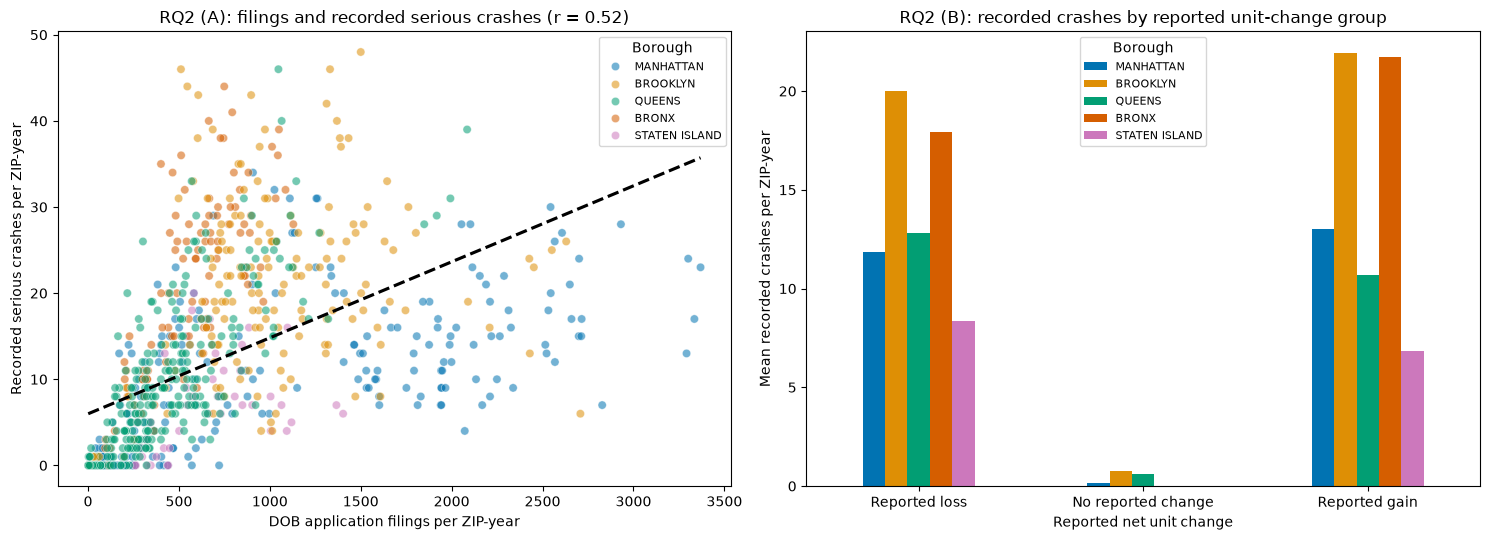

zip_years  mean_crashes
unit_change_group  borough                               
Reported loss      BRONX                 12         17.92
                   BROOKLYN              12         20.00
                   MANHATTAN             65         11.85
                   QUEENS                35         12.80
                   STATEN ISLAND          3          8.33
No reported change BROOKLYN               4          0.75
                   MANHATTAN            145          0.14
                   QUEENS                22          0.59
Reported gain      BRONX                 88         21.75
                   BROOKLYN             140         21.93
                   MANHATTAN            105         13.03
                   QUEENS               200         10.66
                   STATEN ISLAND         45          6.82

,zip_years,Pearson r,Spearman rho
borough,,,
MANHATTAN,315,0.73,0.84
BROOKLYN,156,0.19,0.19
QUEENS,258,0.76,0.78
BRONX,100,0.73,0.72
STATEN ISLAND,48,0.39,0.57


**Exploratory review candidates:** five ZIPs with the highest sum of percentile ranks for four-year reported net units and recorded crashes. This heuristic is not an exposure-adjusted risk score.

,borough,reported_net_units,filings,recorded_crashes,joint_rank_score
zip_code,,,,,
11207,BROOKLYN,13127.0,5713.0,156,1.959276
11101,QUEENS,73865.0,7845.0,127,1.954751
11206,BROOKLYN,14937.0,5506.0,139,1.950226
11212,BROOKLYN,10214.0,4429.0,144,1.914027
10457,BRONX,11707.0,3785.0,128,1.904977


**Finding:** the pooled descriptive Pearson correlation is **0.52**. Spearman correlation is **0.75** across 877 ZIP-years. The unit-change comparison includes 876 ZIP-years with known cohort totals. These comparisons mix places of different size, reporting coverage and activity; no population or traffic exposure is used. Small group cells should not be interpreted as stable estimates. They cannot show that filings cause crashes. Member 3 separately checks changes within places and a one-year lag.

In [2]:
from housing_diagnostics import unit_change_groups
fig, axes = plt.subplots(1, 2, figsize=(15, 5.5))
sns.scatterplot(data=housing_analysis, x="filing_count", y="crash_count", hue="borough",
                hue_order=BOROUGH_ORDER, palette=BOROUGH_COLORS, alpha=0.55, ax=axes[0])
sns.regplot(data=housing_analysis, x="filing_count", y="crash_count", scatter=False, ci=None,
            color="black", line_kws={"linestyle": "--"}, ax=axes[0])
housing_r = housing_analysis["filing_count"].corr(housing_analysis["crash_count"])
housing_rho = housing_analysis["filing_count"].corr(housing_analysis["crash_count"], method="spearman")
axes[0].set(title=f"RQ2 (A): filings and recorded serious crashes (r = {housing_r:.2f})",
       xlabel="DOB application filings per ZIP-year", ylabel="Recorded serious crashes per ZIP-year")
axes[0].legend(title="Borough", fontsize=8)
growth = housing_analysis.dropna(subset=["net_new_units"]).copy()
growth["unit_change_group"] = unit_change_groups(growth["net_new_units"])
group_summary = growth.groupby(["unit_change_group", "borough"], observed=True).agg(
    zip_years=("crash_count", "size"), mean_crashes=("crash_count", "mean"))
group_summary["mean_crashes"].unstack().reindex(columns=BOROUGH_ORDER).plot.bar(
    ax=axes[1], color=[BOROUGH_COLORS[b] for b in BOROUGH_ORDER])
axes[1].set(title="RQ2 (B): recorded crashes by reported unit-change group",
            xlabel="Reported net unit change", ylabel="Mean recorded crashes per ZIP-year")
axes[1].tick_params(axis="x", rotation=0)
axes[1].legend(title="Borough", fontsize=8)
plt.tight_layout()
plt.show()
display(group_summary.round(2))
correlations = []
for borough, group in housing_analysis.groupby("borough"):
    correlations.append({"borough": borough, "zip_years": len(group),
                         "Pearson r": group["filing_count"].corr(group["crash_count"]),
                         "Spearman rho": group["filing_count"].corr(group["crash_count"], method="spearman")})
display(pd.DataFrame(correlations).set_index("borough").reindex(BOROUGH_ORDER).round(2))
zip_totals = housing_analysis.groupby("zip_code").agg(
    borough=("borough", lambda values: values.mode().iloc[0]),
    reported_net_units=("net_new_units", lambda values: values.sum(min_count=1)),
    filings=("filing_count", "sum"), recorded_crashes=("crash_count", "sum"))
zip_totals["joint_rank_score"] = zip_totals["reported_net_units"].rank(pct=True) + zip_totals["recorded_crashes"].rank(pct=True)
display(Markdown("**Exploratory review candidates:** five ZIPs with the highest sum of percentile ranks "
                 "for four-year reported net units and recorded crashes. This heuristic is not an exposure-adjusted risk score."))
display(zip_totals.nlargest(5, "joint_rank_score"))
display(Markdown(f"**Finding:** the pooled descriptive Pearson correlation is **{housing_r:.2f}**. "
                 f"Spearman correlation is **{housing_rho:.2f}** across {len(housing_analysis):,} ZIP-years. "
                 f"The unit-change comparison includes {len(growth):,} ZIP-years with known cohort totals. "
                 "These comparisons mix places of different size, reporting coverage and activity; no population or traffic exposure is used. "
                 "Small group cells should not be interpreted as stable estimates. They cannot show that filings cause crashes. "
                 "Member 3 separately checks changes within places and a one-year lag."))

## 8. Provenance, limitations and contribution
Sources: [H5 housing](https://data.cityofnewyork.us/resource/w9ak-ipjd.json), [T4 SIRTA](https://data.cityofnewyork.us/resource/xeqp-qz8h.json).

Limitations: mutable source snapshots; missing unit pairs; cohort attribution is first observed within this window, not lifetime start; filings and reported units are not completions; approximate ZIP fallback can misclassify boundaries and preferentially cover crash locations; no population/traffic exposure; serious-crash coverage only; correlation is not causation. The optional sensitivity thresholds are judgment calls, not validated corrections, and do not change baseline exports or research charts. Group sizes and reporting coverage vary substantially.

Member 1 provides housing EDA, justified cleaning, job-aware unit accounting, non-mutating sensitivity checks and two research questions with reporting context. AI-assisted correction and validation are recorded in `docs/prompts.md`; original team members should review the regenerated results before submission.